# Weather EDA: Amsterdam, Madrid, Oslo (monthly, 2020–2024)

Reference for what a good agent run produces. The CSVs in `data/` are
verbatim weather `history` tool results (`analysis/capture.sh`).
Build: `nb-build analysis/eda.py` → `analysis/eda.ipynb` + `analysis/results.md`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("data")
CITIES = ["amsterdam", "madrid", "oslo"]
# Fixed categorical order: a city keeps its color in every chart.
COLORS = {"amsterdam": "#2a78d6", "madrid": "#eb6834", "oslo": "#1baf7a"}
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2, "figure.dpi": 110,
})

## 1. Load and validate against the checksum trailer
The tool's last line is `# rows=<n> sum_<var>=<total>`. A mismatch means
rows were dropped or mangled while the CSV was copied into the file.

In [2]:
def load(city: str) -> pd.DataFrame:
    path = DATA / f"{city}.csv"
    trailer = path.read_text().strip().splitlines()[-1].lstrip("# ").split()
    expected = dict(kv.split("=") for kv in trailer)
    df = pd.read_csv(path, comment="#")
    assert len(df) == int(expected["rows"]), f"{city}: {len(df)} rows, expected {expected['rows']}"
    for col in df.columns[1:]:
        got, want = round(df[col].sum(), 1), float(expected[f"sum_{col}"])
        assert abs(got - want) < 0.15, f"{city}: sum_{col} {got} != {want}"
    df["period"] = pd.to_datetime(df["period"])
    df["city"] = city
    return df

df = pd.concat([load(c) for c in CITIES], ignore_index=True)
df["month"] = df["period"].dt.month
print("checksums OK:", {c: len(df[df.city == c]) for c in CITIES})
df.head()

checksums OK: {'amsterdam': 60, 'madrid': 60, 'oslo': 60}


,period,temperature_mean,precipitation,city,month
0,2020-01-01,6.44,58.2,amsterdam,1
1,2020-02-01,6.98,133.2,amsterdam,2
2,2020-03-01,6.40,45.6,amsterdam,3
3,2020-04-01,10.27,23.5,amsterdam,4
4,2020-05-01,12.60,19.5,amsterdam,5


## 2. Summary statistics

In [3]:
summary = df.groupby("city")[["temperature_mean", "precipitation"]].agg(["mean", "min", "max", "std"]).round(1)
summary

temperature_mean                 precipitation                   
                      mean  min   max  std          mean   min    max   std
city                                                                       
amsterdam             11.2  3.4  20.0  5.0          84.4  10.2  176.8  38.4
madrid                15.6  3.3  29.7  7.6          43.3   0.4  162.9  41.6
oslo                   7.0 -7.9  19.2  7.5          79.9   8.5  218.2  46.6

## 3. Time series
Two panels, one measure each (no dual axis).

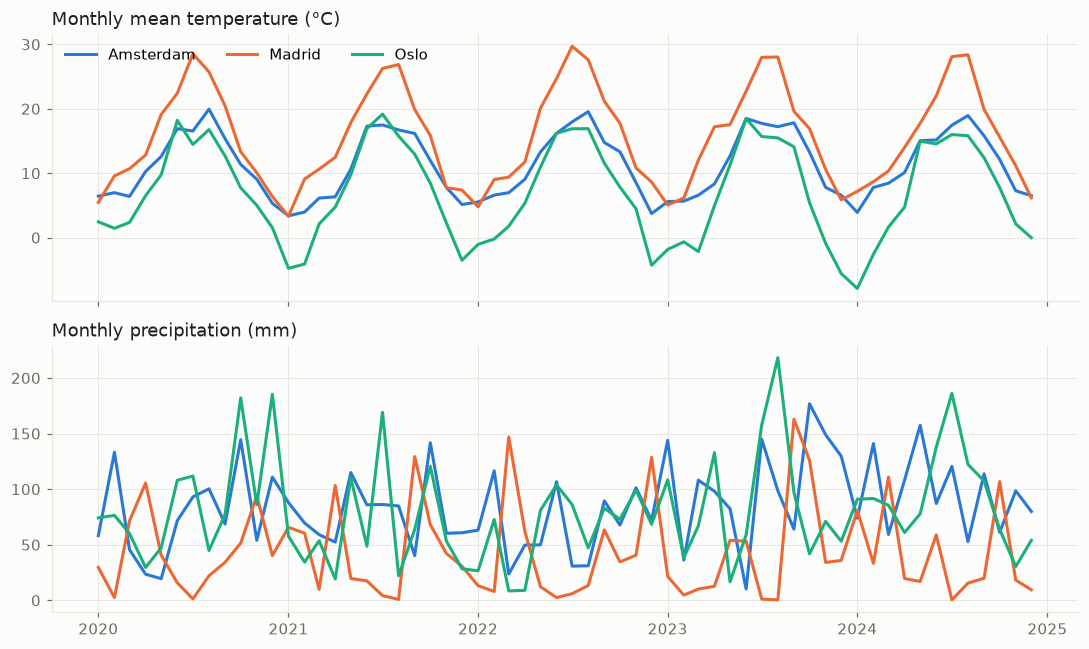

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for city in CITIES:
    d = df[df.city == city]
    axes[0].plot(d.period, d.temperature_mean, color=COLORS[city], label=city.title())
    axes[1].plot(d.period, d.precipitation, color=COLORS[city], label=city.title())
axes[0].set_title("Monthly mean temperature (°C)", loc="left")
axes[1].set_title("Monthly precipitation (mm)", loc="left")
axes[0].legend(frameon=False, ncols=3, loc="upper left")
fig.tight_layout()

## 4. Seasonal profile (month-of-year average)

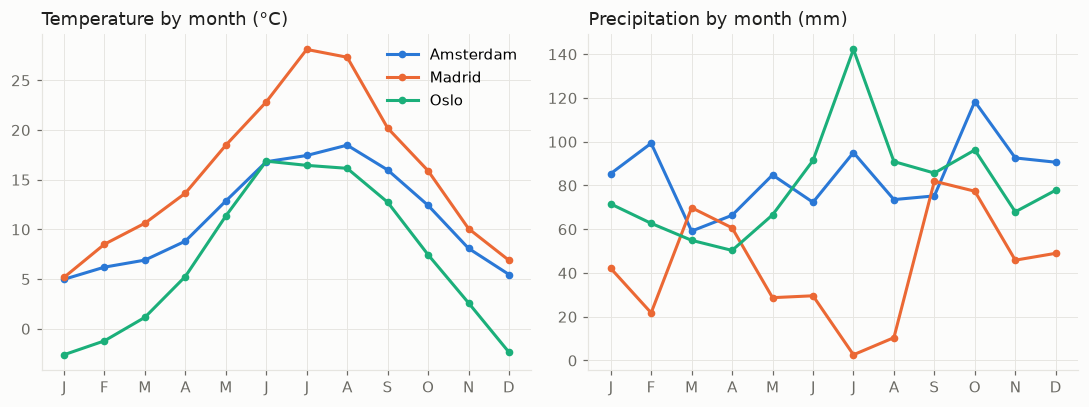

In [5]:
season = df.groupby(["city", "month"])[["temperature_mean", "precipitation"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for city in CITIES:
    s = season.loc[city]
    axes[0].plot(s.index, s.temperature_mean, color=COLORS[city], marker="o", markersize=4, label=city.title())
    axes[1].plot(s.index, s.precipitation, color=COLORS[city], marker="o", markersize=4, label=city.title())
for ax, title in zip(axes, ["Temperature by month (°C)", "Precipitation by month (mm)"]):
    ax.set_title(title, loc="left")
    ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
axes[0].legend(frameon=False)
fig.tight_layout()

## 5. Distributions

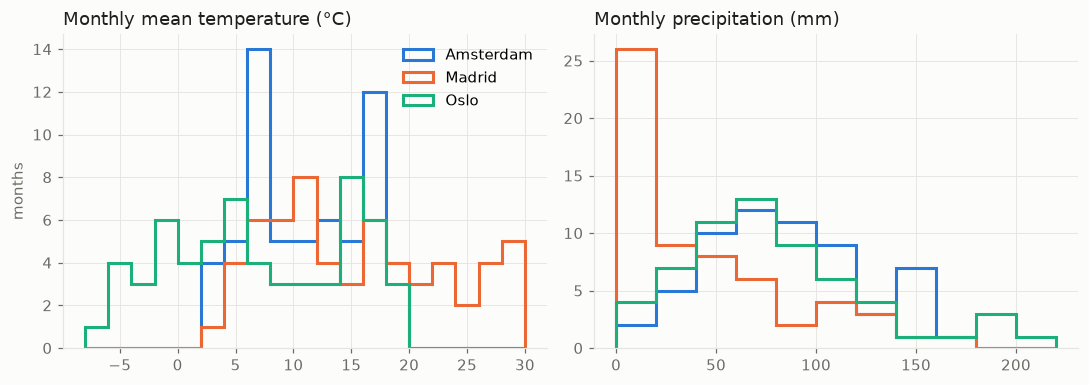

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
# Same bin edges for every city, so the steps line up and compare.
tbins = range(int(df.temperature_mean.min()) - 1, int(df.temperature_mean.max()) + 3, 2)
pbins = range(0, int(df.precipitation.max()) + 21, 20)
for city in CITIES:
    d = df[df.city == city]
    axes[0].hist(d.temperature_mean, bins=tbins, histtype="step", linewidth=2, color=COLORS[city], label=city.title())
    axes[1].hist(d.precipitation, bins=pbins, histtype="step", linewidth=2, color=COLORS[city], label=city.title())
axes[0].set_title("Monthly mean temperature (°C)", loc="left")
axes[1].set_title("Monthly precipitation (mm)", loc="left")
axes[0].set_ylabel("months")
axes[0].legend(frameon=False)
fig.tight_layout()

## 6. Most unusual months
Anomaly = a month's temperature minus that city's 5-year mean for the same calendar month.

In [7]:
df["temp_anomaly"] = df.temperature_mean - df.groupby(["city", "month"]).temperature_mean.transform("mean")
top = (df.assign(abs_anom=df.temp_anomaly.abs()).nlargest(5, "abs_anom")
         [["city", "period", "temperature_mean", "temp_anomaly"]].round(2))
top["period"] = top.period.dt.strftime("%Y-%m")
top

/var/folders/2z/kphzmt991w5_k2bbx33dsz6w0000gn/T/ipykernel_41588/2628010478.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  [["city", "period", "temperature_mean", "temp_anomaly"]].round(2))


,city,period,temperature_mean,temp_anomaly
168,oslo,2024-01,-7.89,-5.28
120,oslo,2020-01,2.45,5.06
131,oslo,2020-12,1.55,3.91
172,oslo,2024-05,14.98,3.63
99,madrid,2023-04,17.21,3.57


## 7. Findings (written to results.md)

In [8]:
lines = ["# Reference EDA results", "",
         "Generated by `nb-build analysis/eda.py` from the verbatim tool output in `analysis/data/`.", "",
         "| City | Rows | Sum temp (trailer) | Mean °C | Coldest month | Warmest month | Wettest month | Total precip 2020–24 (mm) |",
         "|---|---|---|---|---|---|---|---|"]
names = dict(zip(range(1, 13), "Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split()))
for city in CITIES:
    d, s = df[df.city == city], season.loc[city]
    lines.append(f"| {city.title()} | {len(d)} | {d.temperature_mean.sum():.1f} | {d.temperature_mean.mean():.1f} "
                 f"| {names[s.temperature_mean.idxmin()]} {s.temperature_mean.min():.1f} °C "
                 f"| {names[s.temperature_mean.idxmax()]} {s.temperature_mean.max():.1f} °C "
                 f"| {names[s.precipitation.idxmax()]} {s.precipitation.max():.0f} mm | {d.precipitation.sum():.0f} |")
lines += ["", "Most unusual months (temperature vs. that city's 5-year mean for the month):", "",
          "| City | Month | °C | Anomaly °C |", "|---|---|---|---|"]
lines += [f"| {r.city.title()} | {r.period} | {r.temperature_mean:.2f} | {r.temp_anomaly:+.2f} |" for r in top.itertuples()]
Path("results.md").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

# Reference EDA results

Generated by `nb-build analysis/eda.py` from the verbatim tool output in `analysis/data/`.

| City | Rows | Sum temp (trailer) | Mean °C | Coldest month | Warmest month | Wettest month | Total precip 2020–24 (mm) |
|---|---|---|---|---|---|---|---|
| Amsterdam | 60 | 672.2 | 11.2 | Jan 5.0 °C | Aug 18.5 °C | Oct 118 mm | 5064 |
| Madrid | 60 | 938.6 | 15.6 | Jan 5.2 °C | Jul 28.1 °C | Sep 82 mm | 2600 |
| Oslo | 60 | 419.1 | 7.0 | Jan -2.6 °C | Jun 16.9 °C | Jul 142 mm | 4792 |

Most unusual months (temperature vs. that city's 5-year mean for the month):

| City | Month | °C | Anomaly °C |
|---|---|---|---|
| Oslo | 2024-01 | -7.89 | -5.28 |
| Oslo | 2020-01 | 2.45 | +5.06 |
| Oslo | 2020-12 | 1.55 | +3.91 |
| Oslo | 2024-05 | 14.98 | +3.63 |
| Madrid | 2023-04 | 17.21 | +3.57 |
